# 8 · Knowledge-graph visualization  (per article)

Draws the KG produced by the pipeline for one article — **entities as nodes, relations as edges** —
in two forms:

- a **static** matplotlib/networkx figure (`results/<id>/kg_<id>.png`), always available; and
- an **interactive** self-contained pyvis HTML (`results/<id>/kg_<id>.html`) you can drag, zoom, and
  hover (node → type + aliases, edge → property + evidence).

It reads a single self-contained file per article — `relations_ext_consolidated.json` if present, else
`relations_ext.json` (both from nb7) — which already carries both the entity nodes and the relation
edges. Nodes are coloured by **entity type** (a fixed-order categorical palette; the less frequent
types fold into a neutral "Other"); edges are **solid** for schema.org properties and **dashed** for
minted `ex:` (vocab) properties, each labelled with the property name.

In [17]:
# --- Config -------------------------------------------------------------------------------
from pathlib import Path

RESULTS_DIR = Path("results")     # per-article outputs from nb7
ARTICLE_ID  = "art1"              # which article to draw

# Which relations file to read (consolidated preferred — reflects the global re-consolidation pass).
REL_FILES = ["relations_ext_consolidated.json", "relations_ext.json"]

INCLUDE_ISOLATED = True          # False: only entities that take part in >=1 relation (clearer graph)
MAX_TYPE_COLORS  = 8              # distinct type colours; rarer types fold into a neutral "Other"
SHOW_EDGE_LABELS = True           # draw the property name on each edge in the STATIC figure
STATIC_FIGSIZE   = (16, 11)
LAYOUT_SEED      = 42             # reproducible spring layout

# Interactive (pyvis) readability knobs — bump these if labels look small when zoomed out.
NODE_FONT_SIZE   = 40            # node label size (px)
EDGE_FONT_SIZE   = 30            # edge (property) label size (px)
PYVIS_SPRING     = 150           # spring length — larger = more spread out
PYVIS_HEIGHT     = "900px"       # canvas height

def rel_path(aid):
    for name in REL_FILES:
        p = RESULTS_DIR / aid / name
        if p.exists():
            return p
    return None

print("article:", ARTICLE_ID, "| reads one of:", REL_FILES)

article: art1 | reads one of: ['relations_ext_consolidated.json', 'relations_ext.json']


In [18]:
# First run only.
%pip install -q networkx matplotlib pyvis

Note: you may need to restart the kernel to use updated packages.


## 1. Load the graph (self-contained from nb7's relations file)

In [19]:
import json
from collections import Counter

def load_kg(aid, include_isolated=INCLUDE_ISOLATED):
    """Read nb7's relations_ext file and return (nodes, edges).
       nodes: {entity_id: {"label": canonical_text, "type": chosen_type}}
       edges: list of {s, o, property, source, phrases, evidence, confidence}"""
    p = rel_path(aid)
    assert p is not None, f"no relations file for {aid} (expected one of {REL_FILES} under results/{aid}/)"
    data  = json.loads(p.read_text())
    cards = {e["id"]: e for e in data.get("entities", [])}          # id -> {id,text,type,aliases}
    rels  = data.get("relations", [])

    edges = []
    for r in rels:
        edges.append({
            "s": r.get("subject_id"), "o": r.get("object_id"),
            "s_text": r.get("subject_text"), "o_text": r.get("object_text"),
            "s_type": r.get("subject_type"), "o_type": r.get("object_type"),
            "property": r.get("property"), "source": r.get("property_source"),
            "phrases": r.get("relation_phrases", []),
            "evidence": (r.get("evidence") or [None])[0],
            "confidence": r.get("confidence"),
        })

    # node set: everything in an edge, plus (optionally) isolated entities
    used = {e["s"] for e in edges} | {e["o"] for e in edges}
    nodes = {}
    def _node(eid, fallback_text=None, fallback_type=None):
        c = cards.get(eid, {})
        nodes[eid] = {"label": c.get("text") or fallback_text or eid,
                      "type":  c.get("type") or fallback_type or "Unknown"}
    for e in edges:                                                 # prefer the edge's own text/type if a card is missing
        _node(e["s"], e["s_text"], e["s_type"]); _node(e["o"], e["o_text"], e["o_type"])
    if include_isolated:
        for eid in cards:
            if eid not in nodes:
                _node(eid)
    if not include_isolated:
        nodes = {i: v for i, v in nodes.items() if i in used}

    return nodes, edges, str(p.name)

nodes, edges, src = load_kg(ARTICLE_ID)
type_counts = Counter(n["type"] for n in nodes.values())
src_counts  = Counter(e["source"] for e in edges)
print(f"{ARTICLE_ID}: {len(nodes)} nodes, {len(edges)} edges  (from {src})")
print("  node types:", dict(type_counts.most_common(10)), ("..." if len(type_counts) > 10 else ""))
print("  edge sources:", dict(src_counts))

art1: 103 nodes, 95 edges  (from relations_ext_consolidated.json)
  node types: {'Duration': 9, 'DefinedRegion': 9, 'Country': 7, 'City': 6, 'GovernmentOrganization': 6, 'QuantitativeValue': 4, 'Percentage': 4, 'WeatherServiceOrganization': 4, 'DayOfWeek': 4, 'GovernmentOfficial': 3} ...
  edge sources: {'vocab': 59, 'schema.org': 36}


## 2. Colour map — entity type → colour (fixed order, rarer types → "Other")

In [20]:
# Categorical palette (validated, colourblind-checked). Hues are assigned to the MOST FREQUENT types
# in fixed order and never cycled; every rarer type folds into a single neutral "Other" — so identity
# stays legible instead of dissolving into near-duplicate hues.
PALETTE = ["#2a78d6", "#1baf7a", "#eda100", "#008300", "#4a3aa7", "#e34948", "#e87ba4", "#eb6834"]
OTHER_COLOR   = "#9a998f"     # neutral gray for folded-in types
SCHEMA_EDGE   = "#5b5a54"     # schema.org edges (solid)
EX_EDGE       = "#b06a2c"     # minted ex: edges (dashed)
SURFACE       = "#fcfcfb"
INK           = "#0b0b0b"

def build_type_colors(nodes, max_colors=MAX_TYPE_COLORS):
    ranked = [t for t, _ in Counter(n["type"] for n in nodes.values()).most_common()]
    top    = ranked[:max_colors]
    cmap   = {t: PALETTE[i] for i, t in enumerate(top)}
    return cmap, (len(ranked) > len(top))

TYPE_COLORS, HAS_OTHER = build_type_colors(nodes)
def node_color(t):  return TYPE_COLORS.get(t, OTHER_COLOR)
def edge_color(src): return SCHEMA_EDGE if src == "schema.org" else EX_EDGE

print("type -> colour")
for t, c in TYPE_COLORS.items():
    print(f"  {c}  {t}  (x{type_counts[t]})")
if HAS_OTHER:
    n_other = sum(v for t, v in type_counts.items() if t not in TYPE_COLORS)
    print(f"  {OTHER_COLOR}  Other  ({len(type_counts) - len(TYPE_COLORS)} types, {n_other} nodes)")
print("edges: solid = schema.org, dashed = ex: (minted)")

type -> colour
  #2a78d6  Duration  (x9)
  #1baf7a  DefinedRegion  (x9)
  #eda100  Country  (x7)
  #008300  City  (x6)
  #4a3aa7  GovernmentOrganization  (x6)
  #e34948  QuantitativeValue  (x4)
  #e87ba4  Percentage  (x4)
  #eb6834  WeatherServiceOrganization  (x4)
  #9a998f  Other  (38 types, 54 nodes)
edges: solid = schema.org, dashed = ex: (minted)


## 3. Static figure (matplotlib + networkx) → `results/<id>/kg_<id>.png`

saved results/art1/kg_art1.png


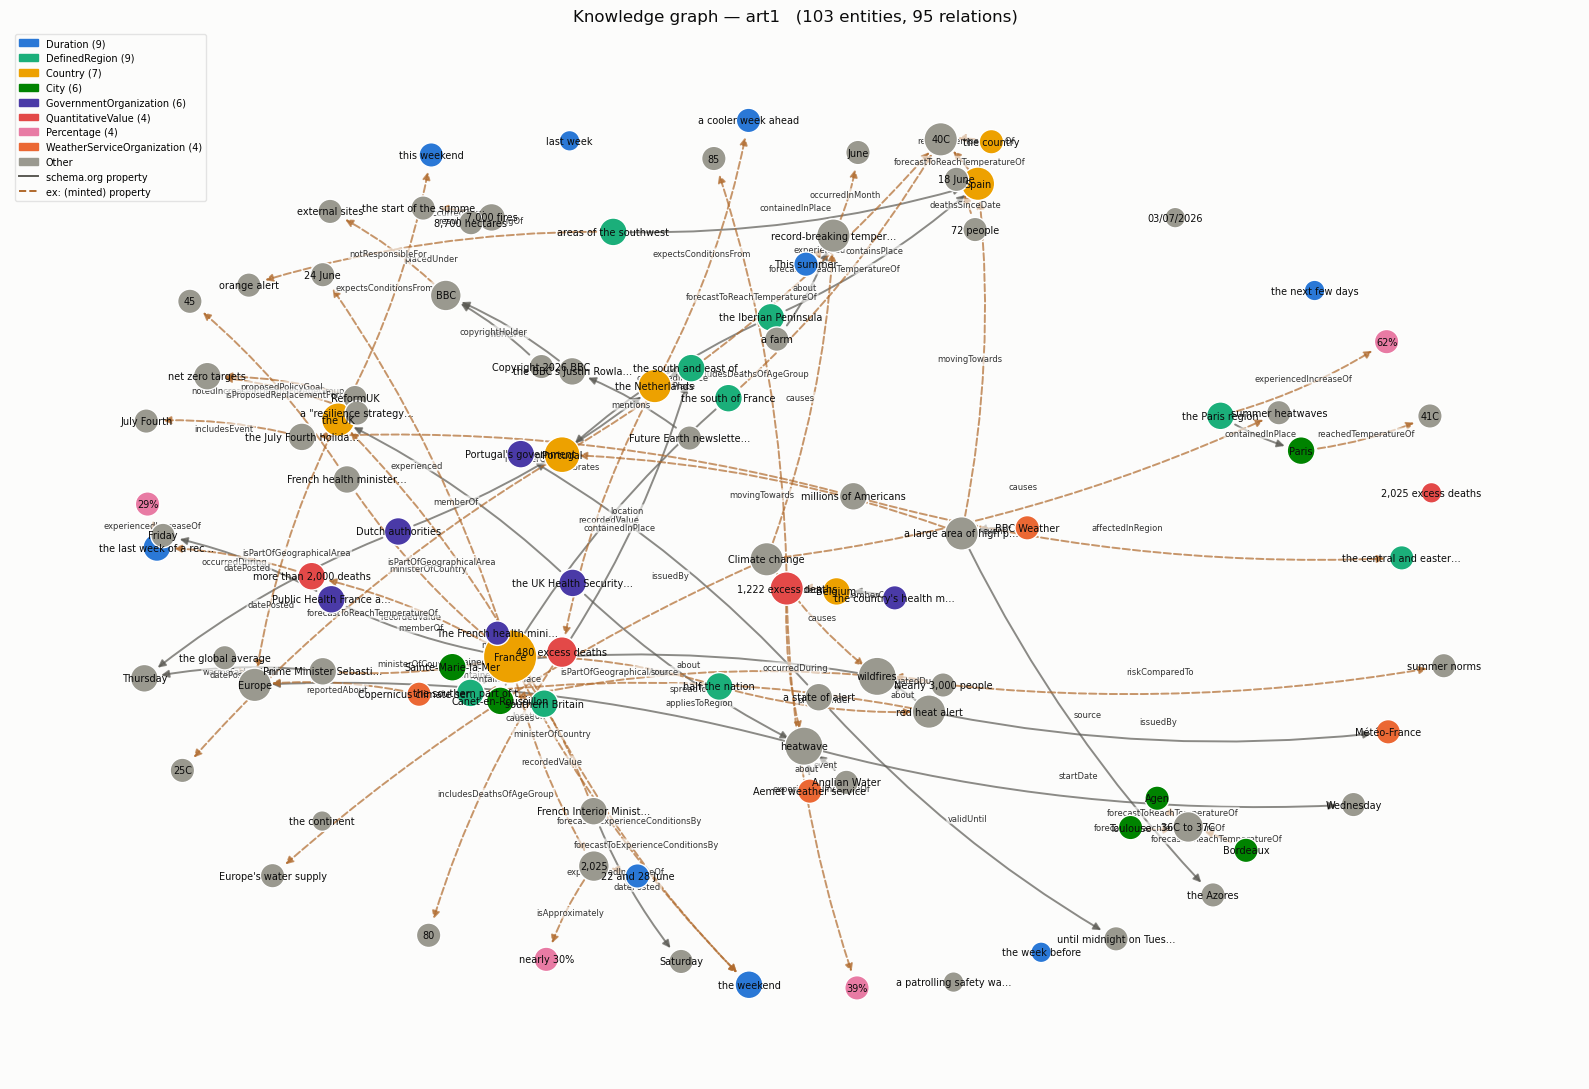

In [21]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import networkx as nx

def draw_static(aid, nodes, edges, show_edge_labels=SHOW_EDGE_LABELS, save=True, show=True):
    G = nx.MultiDiGraph()
    for i, n in nodes.items():
        G.add_node(i, **n)
    for e in edges:
        if e["s"] in nodes and e["o"] in nodes:
            G.add_edge(e["s"], e["o"], property=e["property"], source=e["source"])

    deg = dict(G.degree())
    pos = nx.spring_layout(G, seed=LAYOUT_SEED, k=1.6 / max(len(G) ** 0.5, 1))

    fig, ax = plt.subplots(figsize=STATIC_FIGSIZE)
    fig.patch.set_facecolor(SURFACE); ax.set_facecolor(SURFACE); ax.axis("off")

    nx.draw_networkx_nodes(
        G, pos, ax=ax,
        node_color=[node_color(nodes[i]["type"]) for i in G.nodes()],
        node_size=[220 + 90 * deg.get(i, 0) for i in G.nodes()],
        edgecolors="white", linewidths=1.0)

    for src_kind, dashed in (("schema.org", False), ("ex", True)):
        elist = [(u, v) for u, v, d in G.edges(data=True)
                 if (d.get("source") == "schema.org") == (src_kind == "schema.org")]
        if elist:
            nx.draw_networkx_edges(
                G, pos, ax=ax, edgelist=elist,
                edge_color=(SCHEMA_EDGE if src_kind == "schema.org" else EX_EDGE),
                style=("dashed" if dashed else "solid"),
                width=1.4, alpha=0.7, arrows=True, arrowsize=11,
                connectionstyle="arc3,rad=0.08", node_size=600)

    nx.draw_networkx_labels(
        G, pos, ax=ax, font_size=7, font_color=INK,
        labels={i: (nodes[i]["label"][:22] + ("…" if len(nodes[i]["label"]) > 22 else "")) for i in G.nodes()})

    if show_edge_labels:
        agg = {}                                                   # aggregate parallel edges' labels per (u,v)
        for u, v, d in G.edges(data=True):
            agg.setdefault((u, v), []).append(d.get("property") or "")
        nx.draw_networkx_edge_labels(
            G, pos, ax=ax, font_size=6, font_color="#333333", rotate=False,
            bbox=dict(boxstyle="round,pad=0.15", fc=SURFACE, ec="none", alpha=0.6),
            edge_labels={k: ", ".join(dict.fromkeys(v)) for k, v in agg.items()})

    handles = [mpatches.Patch(color=c, label=f"{t} ({type_counts[t]})") for t, c in TYPE_COLORS.items()]
    if HAS_OTHER:
        handles.append(mpatches.Patch(color=OTHER_COLOR, label="Other"))
    handles += [plt.Line2D([0], [0], color=SCHEMA_EDGE, lw=1.4, label="schema.org property"),
                plt.Line2D([0], [0], color=EX_EDGE, lw=1.4, ls="--", label="ex: (minted) property")]
    ax.legend(handles=handles, loc="upper left", fontsize=7, frameon=True,
              facecolor=SURFACE, edgecolor="#dddddd")
    ax.set_title(f"Knowledge graph — {aid}   ({len(nodes)} entities, {len(edges)} relations)",
                 fontsize=12, color=INK)
    fig.tight_layout()

    if save:
        out = RESULTS_DIR / aid / f"kg_{aid}.png"
        fig.savefig(out, dpi=150, facecolor=SURFACE, bbox_inches="tight")
        print("saved", out)
    if show:
        plt.show()
    else:
        plt.close(fig)

draw_static(ARTICLE_ID, nodes, edges)

## 4. Interactive figure (pyvis) → `results/<id>/kg_<id>.html`

Drag nodes, zoom, and hover — node tooltip shows its type + aliases, edge tooltip shows the property,
its source, the originating relation phrase(s), and the evidence span. The HTML is **self-contained**
(vis.js inlined), so it opens offline.

In [22]:
def draw_interactive(aid, nodes, edges, save=True, show=True):
    try:
        from pyvis.network import Network
    except ImportError:
        print("pyvis not installed — run the %pip cell above (the static PNG above still works).")
        return None
    # count degree for node sizing
    deg = Counter()
    for e in edges:
        if e["s"] in nodes and e["o"] in nodes:
            deg[e["s"]] += 1; deg[e["o"]] += 1

    try:
        net = Network(height=PYVIS_HEIGHT, width="100%", directed=True,
                      bgcolor=SURFACE, font_color=INK, cdn_resources="in_line", notebook=True)
    except TypeError:                                              # older pyvis without some kwargs
        net = Network(height=PYVIS_HEIGHT, width="100%", directed=True, bgcolor=SURFACE, font_color=INK)
    # Big, high-contrast labels (white halo so they read over edges), roomier layout, hover + nav buttons.
    # set_options wants a JSON string; json.dumps guarantees valid JSON (pyvis strips whitespace itself).
    net.set_options(json.dumps({
        "nodes": {"shape": "dot",
                  "font": {"size": NODE_FONT_SIZE, "face": "arial", "color": INK,
                           "strokeWidth": 4, "strokeColor": SURFACE}},
        "edges": {"arrows": {"to": {"enabled": True, "scaleFactor": 0.6}},
                  "color": {"inherit": False, "opacity": 0.8},
                  "smooth": {"enabled": True, "type": "dynamic"},
                  "font": {"size": EDGE_FONT_SIZE, "face": "arial", "color": "#333333",
                           "strokeWidth": 5, "strokeColor": SURFACE, "align": "middle"},
                  "width": 1.5},
        "physics": {"barnesHut": {"gravitationalConstant": -32000, "centralGravity": 0.2,
                                  "springLength": PYVIS_SPRING, "springConstant": 0.02,
                                  "damping": 0.5, "avoidOverlap": 0.7},
                    "minVelocity": 0.75, "stabilization": {"enabled": True, "iterations": 400}},
        "interaction": {"hover": True, "tooltipDelay": 120, "navigationButtons": True, "keyboard": True},
    }))

    for i, n in nodes.items():
        card = f'{n["label"]}  ·  type: {n["type"]}'
        net.add_node(i, label=n["label"], title=card, color=node_color(n["type"]),
                     shape="dot", size=14 + 5 * deg.get(i, 0))
    for e in edges:
        if e["s"] not in nodes or e["o"] not in nodes:
            continue
        tip = f'{e["property"]}  [{e["source"]}]'
        if e["phrases"]:  tip += f'\nphrase(s): {", ".join(e["phrases"])}'
        if e["evidence"]: tip += f'\nevidence: {e["evidence"]}'
        net.add_edge(e["s"], e["o"], label=e["property"] or "", title=tip,
                     color=edge_color(e["source"]), dashes=(e["source"] != "schema.org"),
                     arrows="to")

    out = RESULTS_DIR / aid / f"kg_{aid}.html"
    if save:
        try:
            net.write_html(str(out), notebook=False)              # newer pyvis
        except Exception:
            net.save_graph(str(out))
        print("saved", out)
    if show:
        from IPython.display import IFrame, display
        display(IFrame(src=str(out), width="100%", height="780px"))
    return out

draw_interactive(ARTICLE_ID, nodes, edges)

saved results/art1/kg_art1.html


PosixPath('results/art1/kg_art1.html')

## 5. Triples table (subject → property → object)

In [23]:
# Plain, sorted listing of every edge — the KG as text, for a quick read / copy.
def print_triples(nodes, edges):
    rows = sorted(edges, key=lambda e: (e.get("property") or "", nodes.get(e["s"], {}).get("label", "")))
    print(f"{len(rows)} relations\n" + "-" * 90)
    for e in rows:
        s = nodes.get(e["s"], {}).get("label", e.get("s_text") or e["s"])
        o = nodes.get(e["o"], {}).get("label", e.get("o_text") or e["o"])
        tag = "schema" if e["source"] == "schema.org" else "ex:"
        conf = f'  ({e["confidence"]})' if e.get("confidence") is not None else ""
        print(f'  {s}  --{e["property"]} [{tag}]-->  {o}{conf}')

print_triples(nodes, edges)

95 relations
------------------------------------------------------------------------------------------
  Aemet weather service  --about [schema]-->  heatwave  (1.0)
  a farm  --about [schema]-->  record-breaking temperatures  (1.0)
  red heat alert  --about [schema]-->  wildfires  (1.0)
  the UK Health Security Agency  --about [schema]-->  heatwave  (0.9)
  millions of Americans  --affectedInRegion [ex:]-->  the central and eastern US  (1.0)
  red heat alert  --appliesToRegion [ex:]-->  the southern part of the country  (1.0)
  Climate change  --causes [ex:]-->  record-breaking temperatures  (1.0)
  Climate change  --causes [ex:]-->  summer heatwaves  (1.0)
  Climate change  --causes [ex:]-->  Europe's water supply  (1.0)
  Climate change  --causes [ex:]-->  wildfires  (1.0)
  millions of Americans  --celebrates [ex:]-->  the July Fourth holiday weekend  (1.0)
  Canet-en-Roussillon  --containedInPlace [schema]-->  France  (0.9)
  Sainte-Marie-la-Mer  --containedInPlace [schema]-->  Fr

## 6. Batch — render every article

In [24]:
# Render the static PNG (and interactive HTML) for every article that has an nb7 relations file.
# No inline display — just writes results/<id>/kg_<id>.png and .html.
_articles = sorted({p.parent.name for name in REL_FILES for p in RESULTS_DIR.glob(f"*/{name}")})
print("rendering", len(_articles), "article(s):", _articles)
for aid in _articles:
    n, e, _ = load_kg(aid)
    if not n:
        print(f"  {aid}: no connected entities, skipped"); continue
    # rebuild the per-article type colour map so each figure is self-consistent
    global TYPE_COLORS, HAS_OTHER, type_counts
    type_counts = Counter(v["type"] for v in n.values())
    TYPE_COLORS, HAS_OTHER = build_type_colors(n)
    draw_static(aid, n, e, save=True, show=False)
    draw_interactive(aid, n, e, save=True, show=False)
print("done")

rendering 4 article(s): ['art1', 'art2', 'art4', 'art5']
saved results/art1/kg_art1.png
saved results/art1/kg_art1.html
saved results/art2/kg_art2.png
saved results/art2/kg_art2.html
saved results/art4/kg_art4.png
saved results/art4/kg_art4.html
saved results/art5/kg_art5.png
saved results/art5/kg_art5.html
done
